In [2]:
import os
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Kaggle paths
BASE_PATH = Path("/kaggle/input/datasets/nehalshivane/anemiadataset/AnemiaDataset")
ANERBC_HEALTHY = BASE_PATH / "Healthy_individuals"
ANERBC_ANEMIC = BASE_PATH / "Anemic_individuals"

# Chula / RBC (optional - create if you add datasets later)
CHULA_PATH = BASE_PATH.parent / "Chula-RBC-12" / "Dataset"  # adjust if needed
RBC_PATH = BASE_PATH.parent / "RBC"

print("ANERBC Healthy:", ANERBC_HEALTHY.exists())
print("ANERBC Anemic:", ANERBC_ANEMIC.exists())

ANERBC Healthy: True
ANERBC Anemic: True


In [3]:
def count_images(folder_path):
    folder = Path(folder_path)
    if not folder.exists():
        return 0, []
    extensions = ['jpg', 'jpeg', 'png', 'bmp', 'tif', 'tiff', 'JPG', 'JPEG', 'PNG']
    images = []
    for ext in extensions:
        images.extend(list(folder.rglob(f'*.{ext}')))
    images = list(set(images))
    return len(images), [str(p) for p in images]

anerbc_h_count, anerbc_h_list = count_images(ANERBC_HEALTHY)
anerbc_a_count, anerbc_a_list = count_images(ANERBC_ANEMIC)
chula_count, chula_list = count_images(CHULA_PATH)
rbc_count, rbc_list = count_images(RBC_PATH)

anerbc_total = anerbc_h_count + anerbc_a_count
anerbc_list = anerbc_h_list + anerbc_a_list

print(f"AneRBC Healthy: {anerbc_h_count} images")
print(f"AneRBC Anemic: {anerbc_a_count} images")
print(f"AneRBC Total: {anerbc_total} images")
print(f"Chula-RBC-12: {chula_count} images")
print(f"RBC (Zenodo): {rbc_count} images")

AneRBC Healthy: 6000 images
AneRBC Anemic: 6000 images
AneRBC Total: 12000 images
Chula-RBC-12: 0 images
RBC (Zenodo): 0 images


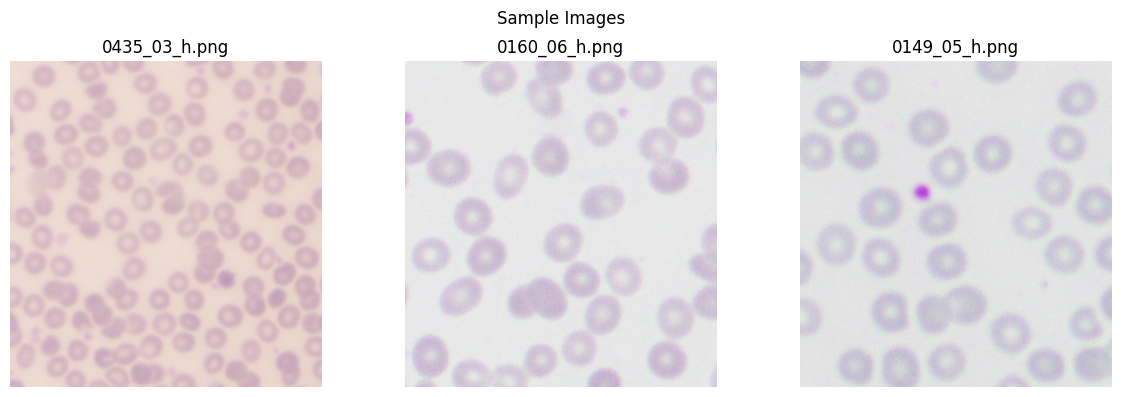

In [4]:
def show_sample(image_paths, title="Sample", cols=3):
    n = min(len(image_paths), cols)
    if n == 0:
        print("No images to show.")
        return
    fig, axes = plt.subplots(1, n, figsize=(4*n, 4))
    if n == 1:
        axes = [axes]
    for i, ax in enumerate(axes):
        img = Image.open(image_paths[i]).convert('RGB')
        ax.imshow(img)
        ax.set_title(Path(image_paths[i]).name[:25])
        ax.axis('off')
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

all_images = anerbc_list or chula_list or rbc_list
if all_images:
    show_sample(all_images[:3], "Sample Images")
else:
    print("No images found. Check paths.")

In [5]:
if anerbc_list or chula_list or rbc_list:
    sample_path = (anerbc_list or chula_list or rbc_list)[0]
    img = Image.open(sample_path)
    print(f"Sample: {Path(sample_path).name}")
    print(f"Size: {img.size} (width x height)")
    print(f"Mode: {img.mode}")
else:
    print("No images to check.")

Sample: 0435_03_h.png
Size: (306, 320) (width x height)
Mode: RGB


In [6]:
summary = pd.DataFrame({
    "Dataset": ["AneRBC Healthy", "AneRBC Anemic", "Chula-RBC-12", "RBC"],
    "Count": [anerbc_h_count, anerbc_a_count, chula_count, rbc_count],
    "Path": [str(ANERBC_HEALTHY), str(ANERBC_ANEMIC), str(CHULA_PATH), str(RBC_PATH)]
})
print(summary.to_string(index=False))
print(f"\nTotal images: {anerbc_total + chula_count + rbc_count}")

       Dataset  Count                                                                                Path
AneRBC Healthy   6000 /kaggle/input/datasets/nehalshivane/anemiadataset/AnemiaDataset/Healthy_individuals
 AneRBC Anemic   6000  /kaggle/input/datasets/nehalshivane/anemiadataset/AnemiaDataset/Anemic_individuals
  Chula-RBC-12      0              /kaggle/input/datasets/nehalshivane/anemiadataset/Chula-RBC-12/Dataset
           RBC      0                               /kaggle/input/datasets/nehalshivane/anemiadataset/RBC

Total images: 12000


In [9]:
!pip install -q staintools

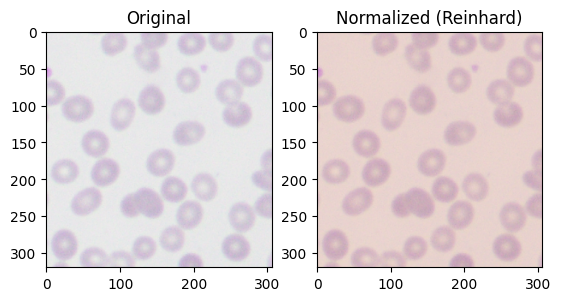

In [10]:
import numpy as np
from PIL import Image
from pathlib import Path

def reinhard_normalize(img_array, reference_path):
    """Reinhard color transfer - no spams dependency."""
    from skimage.color import rgb2lab, lab2rgb
    ref = np.array(Image.open(reference_path).convert('RGB'))
    ref_lab = rgb2lab(ref.astype(np.float32) / 255)
    img_lab = rgb2lab(img_array.astype(np.float32) / 255)
    for i in range(3):
        img_std = img_lab[:,:,i].std() + 1e-8
        ref_std = ref_lab[:,:,i].std() + 1e-8
        img_lab[:,:,i] = (img_lab[:,:,i] - img_lab[:,:,i].mean()) * (ref_std / img_std) + ref_lab[:,:,i].mean()
    return (lab2rgb(img_lab) * 255).clip(0, 255).astype(np.uint8)

# Test
ref_path = anerbc_list[0]
img_path = anerbc_list[1]
img = np.array(Image.open(img_path).convert('RGB'))
normalized = reinhard_normalize(img, ref_path)

fig, axes = plt.subplots(1, 2)
axes[0].imshow(img)
axes[0].set_title("Original")
axes[1].imshow(normalized)
axes[1].set_title("Normalized (Reinhard)")
plt.show()

In [11]:
from sklearn.model_selection import train_test_split

image_paths = []
labels = []
for p in ANERBC_HEALTHY.rglob("*.png"):
    image_paths.append(str(p))
    labels.append(0)
for p in ANERBC_ANEMIC.rglob("*.png"):
    image_paths.append(str(p))
    labels.append(1)
for p in ANERBC_HEALTHY.rglob("*.jpg"):
    image_paths.append(str(p))
    labels.append(0)
for p in ANERBC_ANEMIC.rglob("*.jpg"):
    image_paths.append(str(p))
    labels.append(1)

print(f"Total: {len(image_paths)} | Healthy: {labels.count(0)} | Anemic: {labels.count(1)}")

train_paths, val_paths, train_labels, val_labels = train_test_split(
    image_paths, labels, test_size=0.2, stratify=labels, random_state=42
)
print(f"Train: {len(train_paths)} | Val: {len(val_paths)}")

Total: 12000 | Healthy: 6000 | Anemic: 6000
Train: 9600 | Val: 2400


In [12]:
# Optional: save splits to working dir (Kaggle)
splits_dir = Path("/kaggle/working/splits")
splits_dir.mkdir(parents=True, exist_ok=True)

for name, paths, lbls in [("train", train_paths, train_labels), ("val", val_paths, val_labels)]:
    with open(splits_dir / f"{name}_paths.txt", "w") as f:
        f.write("\n".join(paths))
    with open(splits_dir / f"{name}_labels.txt", "w") as f:
        f.write("\n".join(map(str, lbls)))
print("Saved to /kaggle/working/splits/")

Saved to /kaggle/working/splits/


In [13]:
# Inline data loader - no external src needed
import torch
from torch.utils.data import Dataset
from torchvision import transforms

class PBSDataset(Dataset):
    def __init__(self, image_paths, labels, transform=None):
        self.image_paths = image_paths
        self.labels = labels
        self.transform = transform
    def __len__(self):
        return len(self.image_paths)
    def __getitem__(self, idx):
        img = Image.open(self.image_paths[idx]).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, self.labels[idx]

def get_transforms(train=True):
    if train:
        return transforms.Compose([
            transforms.Resize((224, 224)),
            transforms.RandomHorizontalFlip(),
            transforms.RandomVerticalFlip(),
            transforms.ToTensor(),
            transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
        ])
    else:
        return transforms.Compose([
            transforms.Resize((224, 224)),
            transforms.ToTensor(),
            transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
        ])

from torch.utils.data import DataLoader

train_dataset = PBSDataset(train_paths, train_labels, transform=get_transforms(train=True))
val_dataset = PBSDataset(val_paths, val_labels, transform=get_transforms(train=False))

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=0)

batch_x, batch_y = next(iter(train_loader))
print(f"Batch shape: {batch_x.shape} | Labels: {batch_y.shape}")

Batch shape: torch.Size([32, 3, 224, 224]) | Labels: torch.Size([32])


In [14]:
import torch.nn as nn
from torchvision import models

def get_cnn_model(num_classes=2):
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = get_cnn_model(num_classes=2).to(device)
print(f"Using device: {device}")

Using device: cuda


In [15]:
import torch.nn as nn
from tqdm import tqdm

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = get_cnn_model(num_classes=2).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

epochs = 20
best_val_acc = 0.0

for epoch in range(epochs):
    model.train()
    train_loss, train_correct, train_total = 0.0, 0, 0
    for imgs, labels in tqdm(train_loader, desc="Train"):
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        logits = model(imgs)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()
        train_correct += (logits.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for imgs, labels in val_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            logits = model(imgs)
            loss = criterion(logits, labels)
            val_loss += loss.item()
            val_correct += (logits.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    tr_acc = train_correct / train_total
    val_acc = val_correct / val_total
    print(f"Epoch {epoch+1}/{epochs} | Train Loss: {train_loss/len(train_loader):.4f} Acc: {tr_acc:.4f} | Val Loss: {val_loss/len(val_loader):.4f} Acc: {val_acc:.4f}")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), "/kaggle/working/best_cnn.pt")
        print(f"  -> Saved best CNN (val_acc={val_acc:.4f})")

Train: 100%|██████████| 300/300 [01:24<00:00,  3.55it/s]


Epoch 1/20 | Train Loss: 0.3008 Acc: 0.8571 | Val Loss: 0.1988 Acc: 0.9008
  -> Saved best CNN (val_acc=0.9008)


Train: 100%|██████████| 300/300 [01:20<00:00,  3.75it/s]


Epoch 2/20 | Train Loss: 0.2076 Acc: 0.9007 | Val Loss: 0.1679 Acc: 0.9213
  -> Saved best CNN (val_acc=0.9213)


Train: 100%|██████████| 300/300 [01:21<00:00,  3.69it/s]


Epoch 3/20 | Train Loss: 0.1719 Acc: 0.9195 | Val Loss: 0.1750 Acc: 0.9271
  -> Saved best CNN (val_acc=0.9271)


... (30 outputs left out)

Train: 100%|██████████| 300/300 [01:21<00:00,  3.67it/s]


Epoch 19/20 | Train Loss: 0.0707 Acc: 0.9682 | Val Loss: 0.0987 Acc: 0.9537


Train: 100%|██████████| 300/300 [01:21<00:00,  3.67it/s]


Epoch 20/20 | Train Loss: 0.0775 Acc: 0.9643 | Val Loss: 0.0947 Acc: 0.9537


In [16]:
import numpy as np
from skimage import measure, feature
from skimage.color import rgb2gray
from skimage.filters import threshold_otsu

def extract_morphology(mask):
    props = measure.regionprops(mask.astype(int))
    if not props:
        return np.zeros(6)
    p = props[0]
    area = p.area
    perimeter = p.perimeter
    circularity = 4 * np.pi * area / (perimeter ** 2 + 1e-8)
    eccentricity = p.eccentricity
    solidity = p.solidity
    extent = p.extent
    return np.array([area, perimeter, circularity, eccentricity, solidity, extent])

def extract_glcm(gray_img):
    from skimage.feature import graycomatrix, graycoprops
    gray = (gray_img * 255).astype(np.uint8) if gray_img.max() <= 1 else gray_img.astype(np.uint8)
    glcm = graycomatrix(gray, [1], [0], levels=256, symmetric=True, normed=True)
    contrast = graycoprops(glcm, 'contrast')[0, 0]
    correlation = graycoprops(glcm, 'correlation')[0, 0]
    energy = graycoprops(glcm, 'energy')[0, 0]
    homogeneity = graycoprops(glcm, 'homogeneity')[0, 0]
    return np.array([contrast, correlation, energy, homogeneity])

def extract_color(img_array):
    r, g, b = img_array[:,:,0].mean(), img_array[:,:,1].mean(), img_array[:,:,2].mean()
    gray = rgb2gray(img_array)
    center = gray[gray.shape[0]//4:3*gray.shape[0]//4, gray.shape[1]//4:3*gray.shape[1]//4]
    pallor = (center < center.mean()).sum() / (center.size + 1e-8)
    return np.array([r, g, b, pallor])

def get_mask_from_image(img_array):
    gray = rgb2gray(img_array)
    thresh = threshold_otsu(gray)
    return gray < thresh

def extract_all_features(img_path):
    img = np.array(Image.open(img_path).convert('RGB'))
    gray = rgb2gray(img)
    mask = get_mask_from_image(img)
    morph = extract_morphology(mask)
    texture = extract_glcm(gray)
    color = extract_color(img)
    return np.concatenate([morph, texture, color])

def extract_all_features_from_array(img_array):
    gray = rgb2gray(img_array)
    mask = get_mask_from_image(img_array)
    morph = extract_morphology(mask)
    texture = extract_glcm(gray)
    color = extract_color(img_array)
    return np.concatenate([morph, texture, color])

def extract_features_batch(image_paths):
    features = []
    for path in image_paths:
        try:
            f = extract_all_features(path)
            features.append(f)
        except Exception as e:
            features.append(np.zeros(14))
    return np.array(features, dtype=np.float32)

# Test on one image
feat = extract_all_features(train_paths[0])
print(f"Feature vector shape: {feat.shape}")
print(f"Features: morph(6) + texture(4) + color(4) = 14")

# Test on batch (first 10)
feats = extract_features_batch(train_paths[:10])
print(f"Batch shape: {feats.shape}")

Feature vector shape: (14,)
Features: morph(6) + texture(4) + color(4) = 14
Batch shape: (10, 14)


In [17]:
from torch.utils.data import Dataset
from sklearn.preprocessing import StandardScaler

class HybridDataset(Dataset):
    def __init__(self, image_paths, labels, hand_features, transform=None):
        self.image_paths = image_paths
        self.labels = labels
        self.hand_features = hand_features
        self.transform = transform
    def __len__(self):
        return len(self.image_paths)
    def __getitem__(self, idx):
        img = Image.open(self.image_paths[idx]).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, torch.tensor(self.hand_features[idx], dtype=torch.float32), self.labels[idx]

print("Extracting handcrafted features...")
train_hand = extract_features_batch(train_paths)
val_hand = extract_features_batch(val_paths)

scaler = StandardScaler()
train_hand = scaler.fit_transform(train_hand)
val_hand = scaler.transform(val_hand)

train_ds = HybridDataset(train_paths, train_labels, train_hand, transform=get_transforms(train=True))
val_ds = HybridDataset(val_paths, val_labels, val_hand, transform=get_transforms(train=False))

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=32, shuffle=False, num_workers=0)
print("Hybrid loaders ready.")

Extracting handcrafted features...
Hybrid loaders ready.


In [18]:
class AttentionFusion(nn.Module):
    def __init__(self, cnn_dim, hand_dim, out_dim):
        super().__init__()
        self.proj = nn.Linear(cnn_dim + hand_dim, out_dim)
        self.attention = nn.Sequential(
            nn.Linear(cnn_dim + hand_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 2),
            nn.Softmax(dim=1)
        )
    def forward(self, cnn_feat, hand_feat):
        combined = torch.cat([cnn_feat, hand_feat], dim=1)
        attn = self.attention(combined)
        weighted = torch.cat([attn[:, 0:1] * cnn_feat, attn[:, 1:2] * hand_feat], dim=1)
        return self.proj(weighted), attn

class HybridModel(nn.Module):
    def __init__(self, num_classes=2, pretrained=True):
        super().__init__()
        from torchvision import models
        resnet = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None)
        self.features = nn.Sequential(*list(resnet.children())[:-1])
        cnn_dim = 512
        hand_dim = 14
        self.fusion = AttentionFusion(cnn_dim, hand_dim, 256)
        self.fc = nn.Linear(256, num_classes)
    def forward(self, x, hand_feat):
        feat = self.features(x)
        feat = feat.flatten(1)
        fused, _ = self.fusion(feat, hand_feat)
        return self.fc(fused)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = HybridModel(num_classes=2, pretrained=True).to(device)
criterion = nn.CrossEntropyLoss()

model.train()
for imgs, hand_feat, labels in train_loader:
    imgs, hand_feat, labels = imgs.to(device), hand_feat.to(device), labels.to(device)
    logits = model(imgs, hand_feat)
    loss = criterion(logits, labels)
    print(f"Batch loss: {loss.item():.4f}")
    break
print("Forward pass OK!")

Batch loss: 0.7573
Forward pass OK!


In [19]:
from tqdm import tqdm

num_epochs = 20
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
best_val_acc = 0.0

for epoch in range(num_epochs):
    model.train()
    train_loss, train_correct, train_total = 0.0, 0, 0
    for imgs, hand_feat, labels in tqdm(train_loader, desc="Train"):
        imgs, hand_feat, labels = imgs.to(device), hand_feat.to(device), labels.to(device)
        optimizer.zero_grad()
        logits = model(imgs, hand_feat)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()
        train_correct += (logits.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for imgs, hand_feat, labels in val_loader:
            imgs, hand_feat, labels = imgs.to(device), hand_feat.to(device), labels.to(device)
            logits = model(imgs, hand_feat)
            loss = criterion(logits, labels)
            val_loss += loss.item()
            val_correct += (logits.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    tr_acc = train_correct / train_total
    val_acc = val_correct / val_total
    print(f"Epoch {epoch+1}/{num_epochs} | Train Acc: {tr_acc:.4f} | Val Acc: {val_acc:.4f}")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), "/kaggle/working/best_hybrid.pt")
        print(f"  -> Saved best (val_acc={val_acc:.4f})")

Train: 100%|██████████| 300/300 [01:37<00:00,  3.08it/s]


Epoch 1/20 | Train Acc: 0.8535 | Val Acc: 0.8950
  -> Saved best (val_acc=0.8950)


Train: 100%|██████████| 300/300 [01:27<00:00,  3.42it/s]


Epoch 2/20 | Train Acc: 0.8926 | Val Acc: 0.9187
  -> Saved best (val_acc=0.9187)


Train: 100%|██████████| 300/300 [01:29<00:00,  3.36it/s]


Epoch 3/20 | Train Acc: 0.9161 | Val Acc: 0.9113


... (30 outputs left out)

Train: 100%|██████████| 300/300 [01:21<00:00,  3.66it/s]


Epoch 19/20 | Train Acc: 0.9672 | Val Acc: 0.9571


Train: 100%|██████████| 300/300 [01:21<00:00,  3.69it/s]


Epoch 20/20 | Train Acc: 0.9647 | Val Acc: 0.9487


In [20]:
import joblib
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix, classification_report

joblib.dump(scaler, "/kaggle/working/scaler.pkl")
print("Saved scaler.pkl")

model.load_state_dict(torch.load("/kaggle/working/best_hybrid.pt", map_location=device))
model.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for imgs, hand_feat, labels in val_loader:
        imgs, hand_feat = imgs.to(device), hand_feat.to(device)
        logits = model(imgs, hand_feat)
        preds = logits.argmax(1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

y_pred = np.array(all_preds)
y_true = np.array(all_labels)
acc = (y_pred == y_true).mean()
print(f"Val Accuracy: {acc:.4f}")
print(classification_report(y_true, y_pred, target_names=["Healthy", "Anemic"]))
print(confusion_matrix(y_true, y_pred))

Saved scaler.pkl
Val Accuracy: 0.9629
              precision    recall  f1-score   support

     Healthy       0.97      0.95      0.96      1200
      Anemic       0.95      0.97      0.96      1200

    accuracy                           0.96      2400
   macro avg       0.96      0.96      0.96      2400
weighted avg       0.96      0.96      0.96      2400

[[1144   56]
 [  33 1167]]


In [21]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.


MODEL COMPARISON
Metric          CNN          Hybrid      
---------------------------------------------
Accuracy        0.9692       0.9629      
Precision       0.9697       0.9631      
Recall          0.9692       0.9629      
F1-Score        0.9692       0.9629      


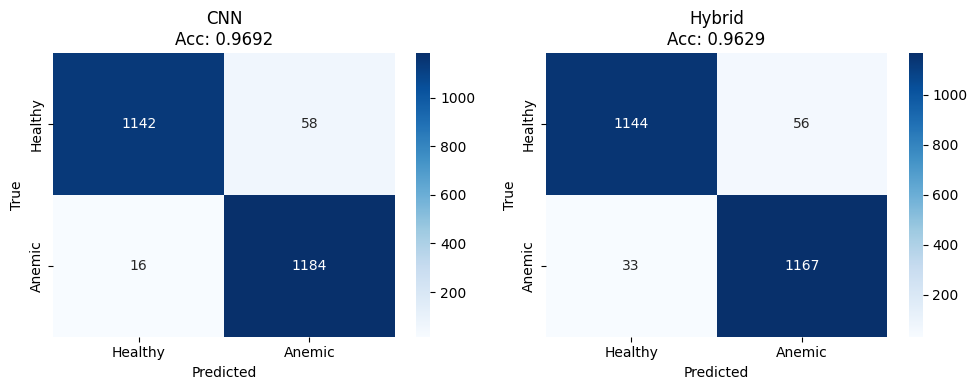

In [22]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, classification_report
import seaborn as sns

CLASS_NAMES = ["Healthy", "Anemic"]

def evaluate_cnn(model, loader, device):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for imgs, labels in loader:
            imgs = imgs.to(device)
            logits = model(imgs)
            preds = logits.argmax(1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())
    return np.array(all_preds), np.array(all_labels)

def evaluate_hybrid(model, loader, device):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for imgs, hand_feat, labels in loader:
            imgs, hand_feat = imgs.to(device), hand_feat.to(device)
            logits = model(imgs, hand_feat)
            preds = logits.argmax(1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())
    return np.array(all_preds), np.array(all_labels)

# CNN: need PBSDataset loader (no handcrafted features)
train_ds_cnn = PBSDataset(train_paths, train_labels, transform=get_transforms(train=True))
val_ds_cnn = PBSDataset(val_paths, val_labels, transform=get_transforms(train=False))
val_loader_cnn = DataLoader(val_ds_cnn, batch_size=32, shuffle=False, num_workers=0)

cnn_model = get_cnn_model(num_classes=2).to(device)
cnn_model.load_state_dict(torch.load("/kaggle/working/best_cnn.pt", map_location=device))

y_pred_cnn, y_true = evaluate_cnn(cnn_model, val_loader_cnn, device)
y_pred_hyb, _ = evaluate_hybrid(model, val_loader, device)

# Metrics
acc_cnn = accuracy_score(y_true, y_pred_cnn)
acc_hyb = accuracy_score(y_true, y_pred_hyb)
p_cnn, r_cnn, f_cnn, _ = precision_recall_fscore_support(y_true, y_pred_cnn, average='macro')
p_hyb, r_hyb, f_hyb, _ = precision_recall_fscore_support(y_true, y_pred_hyb, average='macro')

print("=" * 45)
print("MODEL COMPARISON")
print("=" * 45)
print(f"{'Metric':<15} {'CNN':<12} {'Hybrid':<12}")
print("-" * 45)
print(f"{'Accuracy':<15} {acc_cnn:<12.4f} {acc_hyb:<12.4f}")
print(f"{'Precision':<15} {p_cnn:<12.4f} {p_hyb:<12.4f}")
print(f"{'Recall':<15} {r_cnn:<12.4f} {r_hyb:<12.4f}")
print(f"{'F1-Score':<15} {f_cnn:<12.4f} {f_hyb:<12.4f}")
print("=" * 45)

# Confusion matrices side by side
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
cm_cnn = confusion_matrix(y_true, y_pred_cnn)
cm_hyb = confusion_matrix(y_true, y_pred_hyb)
sns.heatmap(cm_cnn, annot=True, fmt='d', cmap='Blues', ax=axes[0], xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
sns.heatmap(cm_hyb, annot=True, fmt='d', cmap='Blues', ax=axes[1], xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
axes[0].set_title(f"CNN\nAcc: {acc_cnn:.4f}")
axes[1].set_title(f"Hybrid\nAcc: {acc_hyb:.4f}")
axes[0].set_ylabel("True")
axes[0].set_xlabel("Predicted")
axes[1].set_ylabel("True")
axes[1].set_xlabel("Predicted")
plt.tight_layout()
plt.show()

In [23]:
def grad_cam(model, img_tensor, hand_tensor, target_layer):
    model.eval()
    img_tensor = img_tensor.to(device).requires_grad_(True)
    hand_tensor = hand_tensor.to(device)
    activations = []
    def hook(module, input, output):
        activations.append(output)
    h = target_layer.register_forward_hook(hook)
    logits = model(img_tensor, hand_tensor)
    model.zero_grad()
    logits[0, logits.argmax(1).item()].backward()
    cam = activations[0][0].sum(0).detach().cpu().numpy()
    cam = np.maximum(cam, 0)
    cam = cam / (cam.max() + 1e-8)
    h.remove()
    return cam

def overlay_heatmap(img_224, cam, alpha=0.4):
    import cv2
    cam_resized = cv2.resize(cam.astype(np.float32), (img_224.shape[1], img_224.shape[0]))
    cam_colored = plt.cm.jet(cam_resized)[:, :, :3]
    return (alpha * cam_colored + (1 - alpha) * img_224.astype(np.float32) / 255).clip(0, 1)

target_layer = model.features[-2]
print("Grad-CAM ready.")

Grad-CAM ready.


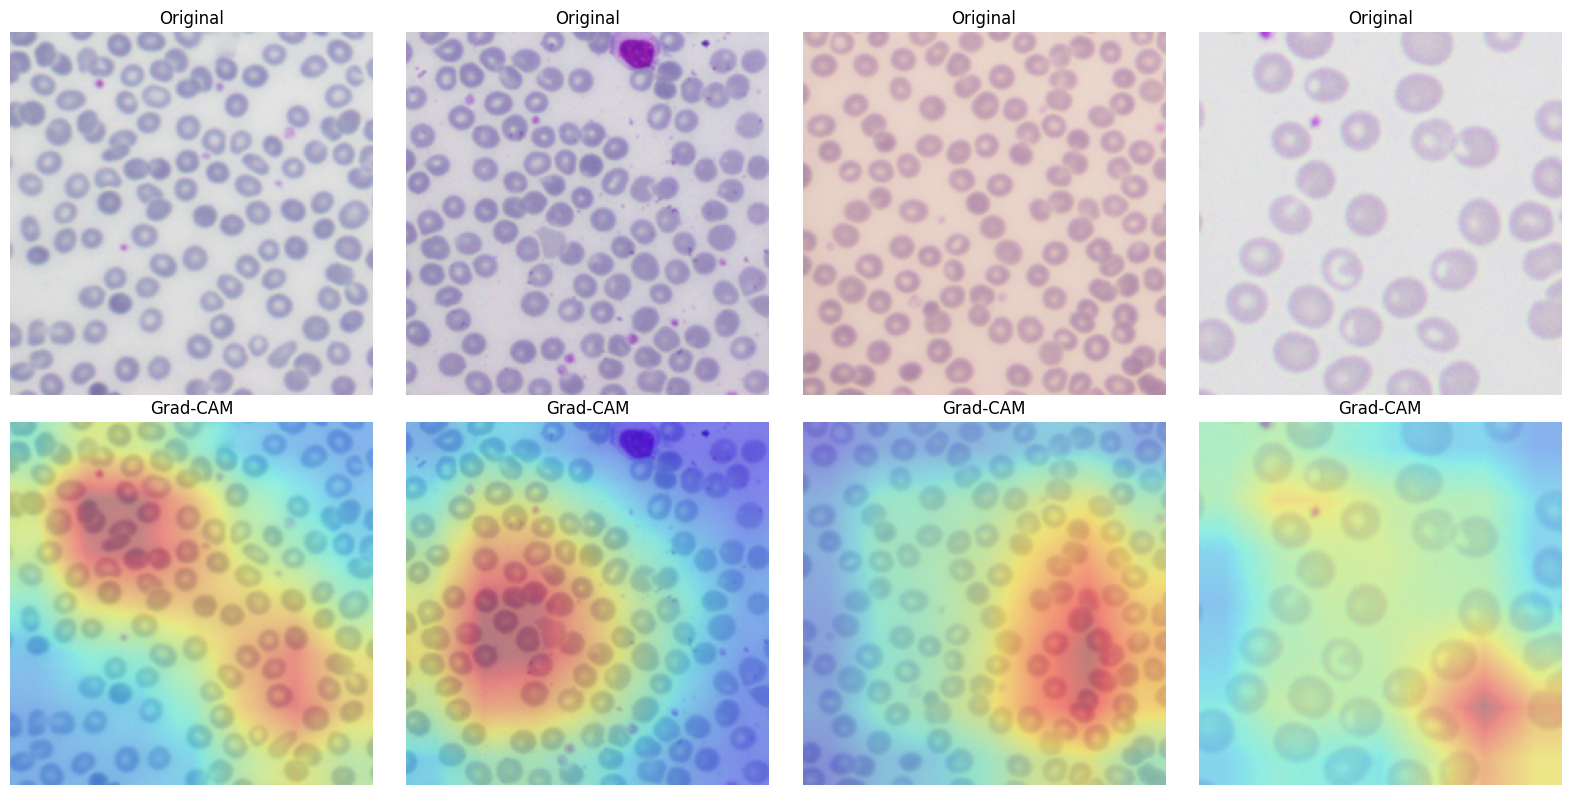

In [24]:
transform = get_transforms(train=False)
n_show = 4
fig, axes = plt.subplots(2, n_show, figsize=(4*n_show, 8))

for i in range(n_show):
    idx = i * 100
    img_path = val_paths[idx]
    img_pil = Image.open(img_path).convert("RGB")
    img_np = np.array(img_pil)
    img_tensor = transform(img_pil).unsqueeze(0)
    hand_raw = extract_all_features(img_path)
    hand_feat = scaler.transform(hand_raw.reshape(1, -1))
    hand_tensor = torch.tensor(hand_feat, dtype=torch.float32)
    cam = grad_cam(model, img_tensor, hand_tensor, target_layer)
    img_224 = np.array(Image.fromarray(img_np).resize((224, 224)))
    overlay_img = overlay_heatmap(img_224, cam)
    axes[0, i].imshow(img_224)
    axes[0, i].set_title("Original")
    axes[0, i].axis("off")
    axes[1, i].imshow(overlay_img)
    axes[1, i].set_title("Grad-CAM")
    axes[1, i].axis("off")

plt.tight_layout()
plt.savefig("/kaggle/working/gradcam_samples.png", dpi=150)
plt.show()

In [25]:
CLASS_NAMES = ["Healthy", "Anemic"]
idx = 0
img_path = val_paths[idx]
true_label = val_labels[idx]

img_pil = Image.open(img_path).convert("RGB")
img_tensor = get_transforms(train=False)(img_pil).unsqueeze(0).to(device)
hand_raw = extract_all_features(img_path)
hand_feat = scaler.transform(hand_raw.reshape(1, -1))
hand_tensor = torch.tensor(hand_feat, dtype=torch.float32).to(device)

model.eval()
with torch.no_grad():
    logits = model(img_tensor, hand_tensor)
    probs = torch.softmax(logits, dim=1)
    pred = logits.argmax(1).item()
    confidence = probs[0, pred].item()

print("="*50)
print("PIPELINE TEST")
print("="*50)
print(f"Image: {Path(img_path).name}")
print(f"True label:  {CLASS_NAMES[true_label]} ({true_label})")
print(f"Prediction:  {CLASS_NAMES[pred]} ({pred})")
print(f"Confidence:  {confidence:.4f}")
print(f"Match:       {'✓ CORRECT' if pred == true_label else '✗ WRONG'}")
print("="*50)

PIPELINE TEST
Image: 0086_10_h.png
True label:  Healthy (0)
Prediction:  Healthy (0)
Confidence:  1.0000
Match:       ✓ CORRECT


Enter image path:  /kaggle/input/datasets/nehalshivane/anemiadataset/AnemiaDataset/Healthy_individuals/Original_images/0002_11_h.png


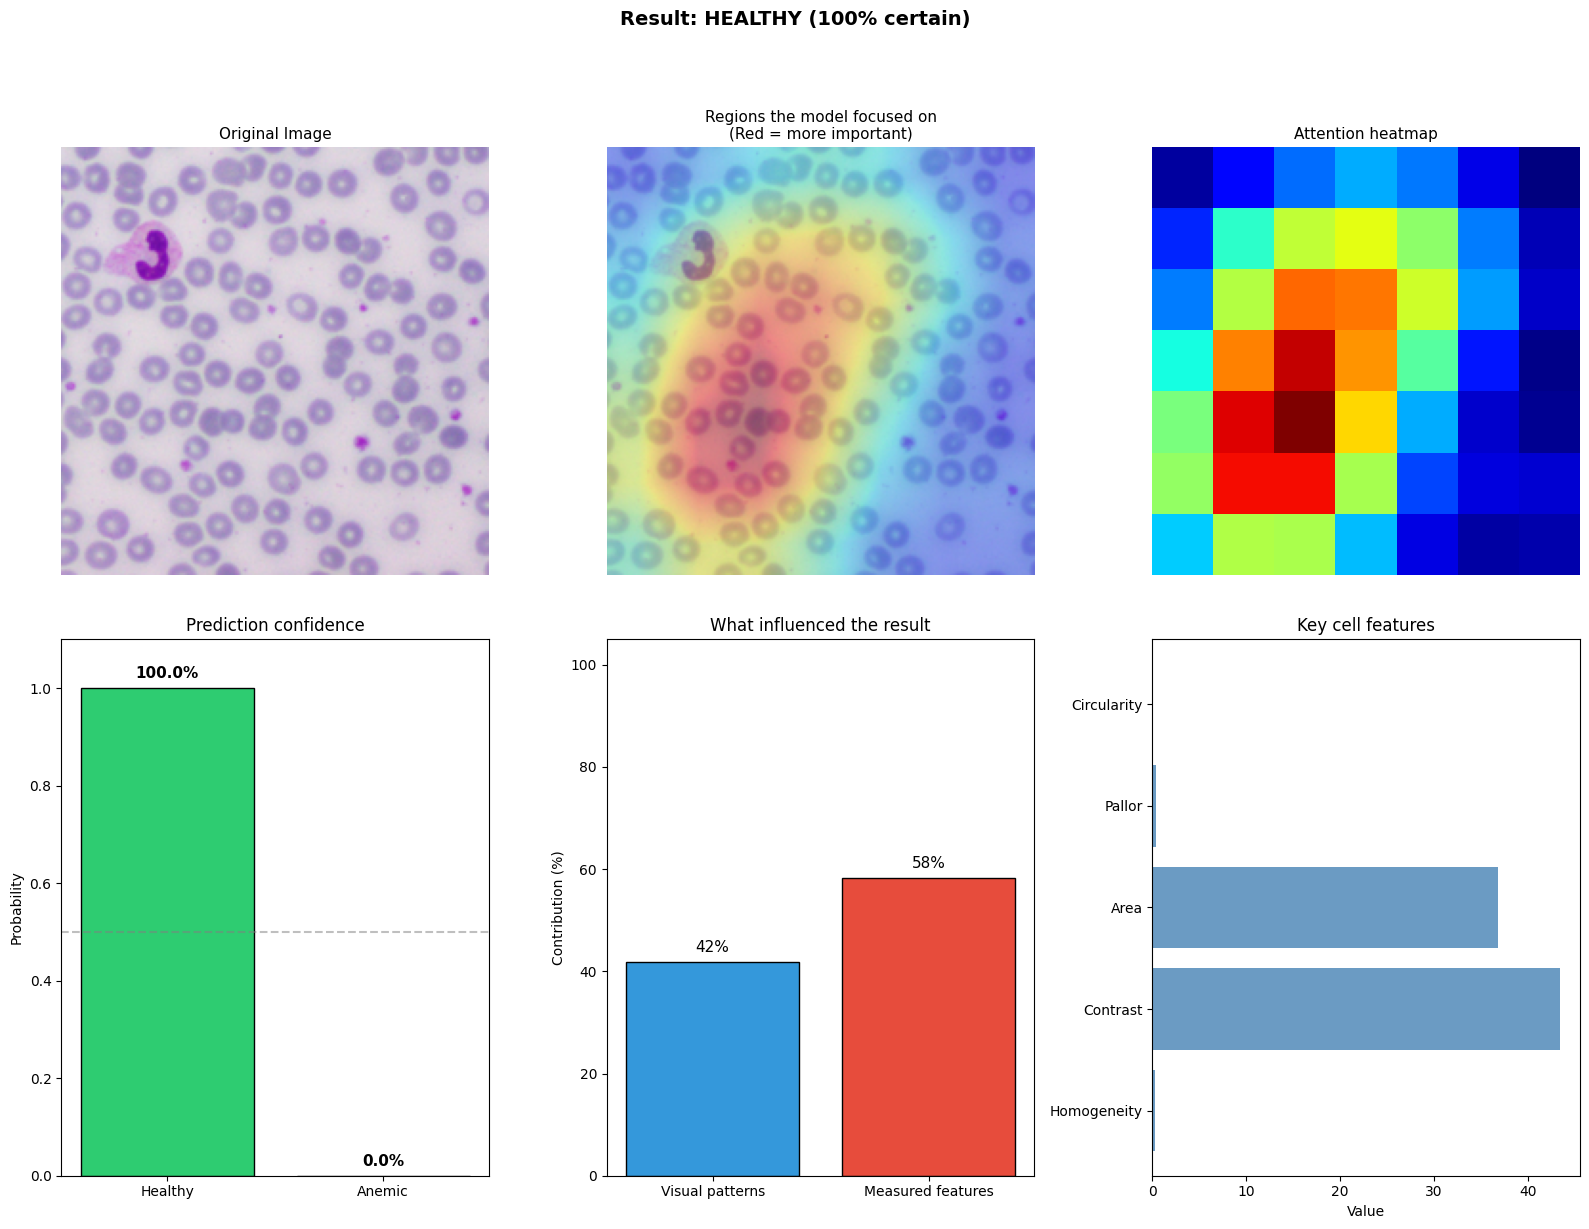


  BLOOD SMEAR ANALYSIS RESULT

  Image analysed: 0002_11_h.png

  Result: HEALTHY
  Certainty: 100%

------------------------------------------------------------
  What influenced this result
------------------------------------------------------------

  • Visual pattern analysis: 42%
  • Measured cell features:  58%

  Cell features observed:
    - Shape (roundness):     More irregular
    - Central pallor:        More noticeable
    - Cell size:             Normal

  Note: This is a screening aid. Please consult a doctor
  for diagnosis and treatment.

  TECHNICAL DETAILS
Image: 0002_11_h.png
Prediction:  Healthy (0)
Confidence:  1.0000 (100.00%)

------------------------------------------------------------
ATTENTION WEIGHTS
------------------------------------------------------------
  CNN features:         41.74%
  Handcrafted features: 58.26%

------------------------------------------------------------
HANDCRAFTED FEATURES
-------------------------------------------------------

In [28]:
CLASS_NAMES = ["Healthy", "Anemic"]
FEATURE_NAMES = [
    "area", "perimeter", "circularity", "eccentricity", "solidity", "extent",
    "contrast", "correlation", "energy", "homogeneity",
    "mean_R", "mean_G", "mean_B", "pallor_ratio"
]

input_image_path = input("Enter image path: ").strip().strip('"').strip("'")

img_pil = Image.open(input_image_path).convert("RGB")
img_np = np.array(img_pil)
transform = get_transforms(train=False)
img_tensor = transform(img_pil).unsqueeze(0)

hand_raw = extract_all_features(input_image_path)
hand_feat = scaler.transform(hand_raw.reshape(1, -1))
hand_tensor = torch.tensor(hand_feat, dtype=torch.float32)

target_layer = model.features[-2]
cam = grad_cam(model, img_tensor, hand_tensor, target_layer)

img_224 = np.array(Image.fromarray(img_np).resize((224, 224)))
overlay = overlay_heatmap(img_224, cam)

model.eval()
with torch.no_grad():
    cnn_feat = model.features(img_tensor.to(device))
    cnn_flat = cnn_feat.flatten(1)
    combined = torch.cat([cnn_flat, hand_tensor.to(device)], dim=1)
    attn = model.fusion.attention(combined)
    attn_cnn = attn[0, 0].item()
    attn_hand = attn[0, 1].item()
    logits = model(img_tensor.to(device), hand_tensor.to(device))
    probs = torch.softmax(logits, dim=1)
    pred = logits.argmax(1).item()
    confidence = probs[0, pred].item()

result = "ANEMIC" if pred == 1 else "HEALTHY"
certainty = int(round(confidence * 100))

# ========== ENHANCED PLOTS ==========
fig = plt.figure(figsize=(16, 12))

ax1 = fig.add_subplot(2, 3, 1)
ax1.imshow(img_224)
ax1.set_title("Original Image", fontsize=11)
ax1.axis("off")

ax2 = fig.add_subplot(2, 3, 2)
ax2.imshow(overlay)
ax2.set_title("Regions the model focused on\n(Red = more important)", fontsize=11)
ax2.axis("off")

ax3 = fig.add_subplot(2, 3, 3)
ax3.imshow(cam, cmap='jet')
ax3.set_title("Attention heatmap", fontsize=11)
ax3.axis("off")

ax4 = fig.add_subplot(2, 3, 4)
probs_np = probs.cpu().numpy()[0]
colors = ['#2ecc71' if i == pred else '#bdc3c7' for i in range(2)]
bars = ax4.bar(CLASS_NAMES, probs_np, color=colors, edgecolor='black')
ax4.set_ylabel("Probability")
ax4.set_title("Prediction confidence")
ax4.set_ylim(0, 1.1)
for bar, p in zip(bars, probs_np):
    ax4.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02, 
             f'{p:.1%}', ha='center', fontsize=11, fontweight='bold')
ax4.axhline(y=0.5, color='gray', linestyle='--', alpha=0.5)

ax5 = fig.add_subplot(2, 3, 5)
attn_vals = [attn_cnn * 100, attn_hand * 100]
attn_labels = ['Visual patterns', 'Measured features']
colors_attn = ['#3498db', '#e74c3c']
bars2 = ax5.bar(attn_labels, attn_vals, color=colors_attn, edgecolor='black')
ax5.set_ylabel("Contribution (%)")
ax5.set_title("What influenced the result")
ax5.set_ylim(0, 105)
for bar, v in zip(bars2, attn_vals):
    ax5.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2, 
             f'{v:.0f}%', ha='center', fontsize=11)

ax6 = fig.add_subplot(2, 3, 6)
key_names = ['Circularity', 'Pallor', 'Area', 'Contrast', 'Homogeneity']
key_vals = [hand_raw[2], hand_raw[13], hand_raw[0]/1000, hand_raw[6], hand_raw[9]]
ax6.barh(key_names, key_vals, color='steelblue', alpha=0.8)
ax6.set_xlabel("Value")
ax6.set_title("Key cell features")
ax6.invert_yaxis()

plt.suptitle(f"Result: {result} ({certainty}% certain)", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# ========== NON-TECHNICAL OUTPUT ==========
print()
print("="*60)
print("  BLOOD SMEAR ANALYSIS RESULT")
print("="*60)
print()
print(f"  Image analysed: {Path(input_image_path).name}")
print()
print(f"  Result: {result}")
print(f"  Certainty: {certainty}%")
print()
print("-"*60)
print("  What influenced this result")
print("-"*60)
print()
print(f"  • Visual pattern analysis: {attn_cnn*100:.0f}%")
print(f"  • Measured cell features:  {attn_hand*100:.0f}%")
print()
print("  Cell features observed:")
print(f"    - Shape (roundness):     {'More irregular' if hand_raw[2] < 0.85 else 'More round'}")
print(f"    - Central pallor:        {'More noticeable' if hand_raw[13] > 0.15 else 'Less noticeable'}")
print(f"    - Cell size:             {'Smaller' if hand_raw[0] < 1000 else 'Normal'}")
print()
print("="*60)
print("  Note: This is a screening aid. Please consult a doctor")
print("  for diagnosis and treatment.")
print("="*60)

# ========== TECHNICAL OUTPUT ==========
print()
print("="*60)
print("  TECHNICAL DETAILS")
print("="*60)
print(f"Image: {Path(input_image_path).name}")
print(f"Prediction:  {CLASS_NAMES[pred]} ({pred})")
print(f"Confidence:  {confidence:.4f} ({confidence*100:.2f}%)")
print()
print("-"*60)
print("ATTENTION WEIGHTS")
print("-"*60)
print(f"  CNN features:         {attn_cnn:.2%}")
print(f"  Handcrafted features: {attn_hand:.2%}")
print()
print("-"*60)
print("HANDCRAFTED FEATURES")
print("-"*60)
for i, name in enumerate(FEATURE_NAMES):
    print(f"  {name:<18} {hand_raw[i]:>10.4f}")
print("="*60)